# Machine Learning — Sesioni 3

## Klasifikimi — Logistic Regression + Confusion Matrix

**Dataseti:** `employees_churn.csv`

**Target:** `churn` (1 = Rating < 3, 0 = qëndron)


##  Setup

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

df = pd.read_csv('../data/employees_churn.csv')
print(f'Shape: {df.shape}')
print(df['churn'].value_counts())


Shape: (350, 11)
churn
1    176
0    174
Name: count, dtype: int64


## Përgatitim X (pa Rating!) dhe y

In [2]:
X = pd.get_dummies(df[['Mosha', 'Bonus', 'vite_pune', 'Departamenti']], drop_first=True)
y = df['churn']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y)

print(f'Veçori: {X.shape[1]} kolona')
print(f'Train: {X_train.shape[0]} ({y_train.sum()} churn) | Test: {X_test.shape[0]} ({y_test.sum()} churn)')


Veçori: 8 kolona
Train: 280 (141 churn) | Test: 70 (35 churn)


## Trajnojmë Logistic Regression

### Imagjinoni sikur po ecni drejt një destinacioni. Çdo iterim është një hap. max_iter tregon sa hapa maksimum mund të bëni.

1. max_iter = 10 → Lejohen maksimumi 10 hapa. Nëse nuk arrin destinacionin brenda 10 hapave, algoritmi ndalet.
2. max_iter = 100 → Lejohen maksimumi 100 hapa. Zakonisht kjo është e mjaftueshme për të arritur destinacionin.
3. max_iter = 1000 → Ke deri në 1000 hapa, por nëse arrin destinacionin pas 42 hapash, algoritmi ndalet menjëherë. Nuk i përdor të gjitha 1000 hapat.

In [3]:
model = LogisticRegression(max_iter=1000)
model.fit(X_train, y_train)

proba = model.predict_proba(X_test)[:, 1]
y_pred = model.predict(X_test)

print('Probabiliteti për 5 punonjësit e parë:')
for i in range(5):
    print(f'  proba={proba[i]:.3f} → pred={y_pred[i]}, reale={y_test.iloc[i]}')


Probabiliteti për 5 punonjësit e parë:
  proba=0.799 → pred=1, reale=1
  proba=0.704 → pred=1, reale=1
  proba=0.453 → pred=0, reale=1
  proba=0.087 → pred=0, reale=1
  proba=0.770 → pred=1, reale=0


##  Confusion Matrix

In [4]:
cm = confusion_matrix(y_test, y_pred)
tn, fp, fn, tp = cm.ravel()
print(f'TN={tn}, FP={fp}, FN={fn}, TP={tp}')
print('FN = humbëm largime | FP = alarme të rreme')


TN=24, FP=11, FN=12, TP=23
FN = humbëm largime | FP = alarme të rreme


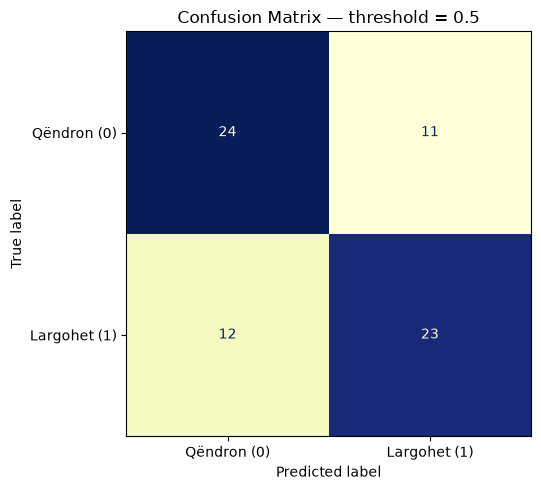

In [5]:
fig, ax = plt.subplots(figsize=(6, 5))
ConfusionMatrixDisplay(cm, display_labels=['Qëndron (0)', 'Largohet (1)']).plot(
    ax=ax, cmap='YlGnBu', values_format='d', colorbar=False)
plt.title('Confusion Matrix — threshold = 0.5')
plt.tight_layout()
plt.show()


##  Threshold-e të ndryshme (0.3, 0.5, 0.7)

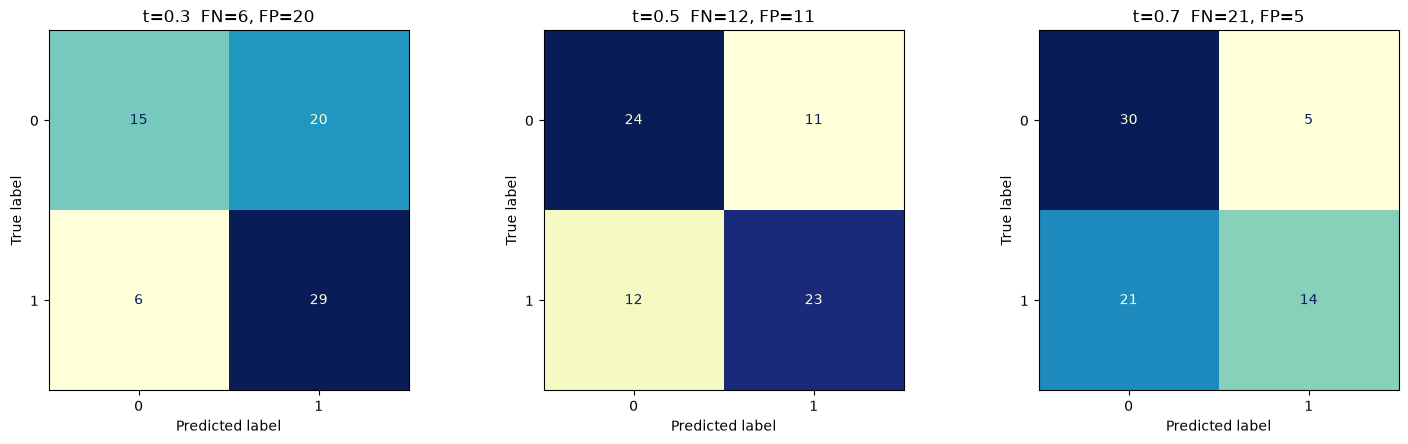

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))

for ax, t in zip(axes, [0.3, 0.5, 0.7]):
    y_pred_t = (proba >= t).astype(int)
    cm_t = confusion_matrix(y_test, y_pred_t)
    tn, fp, fn, tp = cm_t.ravel()
    ConfusionMatrixDisplay(cm_t, display_labels=['0', '1']).plot(
        ax=ax, cmap='YlGnBu', colorbar=False, values_format='d')
    ax.set_title(f't={t}  FN={fn}, FP={fp}')

plt.tight_layout()
plt.show()


###  Çka shohim?
- Threshold i ulët → më shumë TP por edhe FP
- Për HR, FN (humb largime) është më keq → threshold më i ulët

### Ushtrimi 1 — Ndryshoni Threshold

1. Vendosni threshold = 0.25 në vend të 0.50.
2. Krijoni parashikimet (y_pred).
3. Kalkuloni Confusion Matrix.
4. A u rrit numri i False Positives apo False Negatives krahasuar me threshold = 0.50?

### Ushtrimi 2 — Gjeni Threshold që minimizon False Negatives

1. Testoni threshold nga 0.10 deri në 0.85.
2. Për secilin threshold llogaritni False Negatives.
3. Gjeni threshold-in që jep numrin më të vogël të False Negatives.
4. A mendoni se ky threshold është zgjedhja më e mirë për HR?

### Ushtrimi 3 — HR ka Vetëm 10 Bonuse

1. Renditni punonjësit sipas probabilitetit të churn.
2. Zgjidhni vetëm 10 me probabilitetin më të lartë.
3. Pse do t'i zgjidhnit pikërisht këta punonjës?

### Ushtrimi 4 — Ndryshoni test_size

1. Ndajeni dataset-in me test_size = 0.30.
2. Trajnoni modelin.
3. Kalkuloni Accuracy dhe Confusion Matrix.
4. Krahasoni rezultatet me test_size = 0.20.